Se va responder los siguientes conceptos típicos de un ejercicio de seguimiento:

1. ¿Cambió la población?
2. ¿Cambió la calidad de datos?
3. ¿Cambió la relación variable-default?
4. ¿Cayó el poder discriminante temporal?
5. ¿Dónde no funciona bien el modelo?
6. ¿Qué variables explican la caída del Gini?
7. ¿Existe un grupo con default superior al apetito de riesgo, aunque la PD esté calibrada?



In [1]:
!pip install lightgbm shap optuna plotly scikit-learn pandas numpy scipy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 12.7 MB/s eta 0:00:00


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from scipy import stats
from scipy.spatial.distance import mahalanobis
from scipy.linalg import pinv

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

try:
    import lightgbm as lgb
    HAS_LGB = True
except Exception:
    HAS_LGB = False

try:
    import shap
    HAS_SHAP = True
except Exception:
    HAS_SHAP = False

pd.set_option('display.max_columns', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [3]:
# Ventanas temporales
TRAIN_MONTHS = pd.period_range('2024-01', '2024-12', freq='M').astype(str).tolist()
OOT_MONTHS   = pd.period_range('2025-01', '2025-06', freq='M').astype(str).tolist()
ALL_MONTHS   = TRAIN_MONTHS + OOT_MONTHS

# Apetito de riesgo
RISK_APPETITE_BAD_RATE = 0.10  # máximo default tolerado por cada segmento
MIN_SEGMENT_SIZE = 300         # evita falsos hallazgos por segmentos pequeños

# Top 1% mejores clientes: menor PD predicha en train
TOP_PERCENTILE = 0.01

print('Train:', TRAIN_MONTHS[0], 'a', TRAIN_MONTHS[-1])
print('OOT  :', OOT_MONTHS[0], 'a', OOT_MONTHS[-1])


Train: 2024-01 a 2024-12
OOT  : 2025-01 a 2025-06


Universo de clientes con ciertas particularidades vistos en seguimiento, como por ejemplo:

- Variables numéricas y categóricas.
- Missings evolutivos.
- Outliers.
- Drift poblacional en OOT.
- Relación más débil de algunas variables con default en OOT.
- Un segmento de clientes con default alto pero PD aparentemente calibrada.


In [4]:
def simulate_month(period, n=5000, seed=42):
    rng = np.random.default_rng(seed + int(period.replace('-', '')))
    month_idx = ALL_MONTHS.index(period)
    is_oot = period in OOT_MONTHS
    oot_idx = OOT_MONTHS.index(period) + 1 if is_oot else 0

    # Drift gradual en OOT
    macro_stress = max(0, oot_idx) / max(1, len(OOT_MONTHS)) #para simular que el entorno económico empeora con el tiempo.

    edad = rng.normal(38 + 0.15*month_idx, 10, n).clip(21, 75)
    ingreso = rng.lognormal(mean=np.log(4500 - 350*macro_stress), sigma=0.45, size=n)
    ingreso = ingreso.clip(800, 25000)

    bureau = rng.normal(665 - 35*macro_stress, 75 + 8*macro_stress, n).clip(300, 900)
    utilizacion_tc = rng.beta(2.1 + 0.6*macro_stress, 5.0 - 0.8*macro_stress, n).clip(0, 1)
    endeudamiento = rng.beta(2.4 + 0.8*macro_stress, 6.0 - 0.5*macro_stress, n).clip(0, 1)
    antiguedad_laboral = rng.exponential(4.2 - 0.6*macro_stress, n).clip(0, 25)
    num_consultas = rng.poisson(1.2 + 1.0*macro_stress, n)
    mora_hist_12m = rng.poisson(0.35 + 0.45*macro_stress, n).clip(0, 8)

    producto = rng.choice(['TC', 'CE', 'PYME', 'Hipotecario'], p=[0.42, 0.30, 0.18, 0.10], size=n)
    canal = rng.choice(['Digital', 'Agencia', 'Televentas', 'Aliado'], p=[0.38+0.10*macro_stress, 0.32-0.06*macro_stress, 0.18, 0.12-0.04*macro_stress], size=n)
    region = rng.choice(['Lima', 'Norte', 'Sur', 'Centro', 'Oriente'], p=[0.48, 0.20, 0.14, 0.10, 0.08], size=n)

    # Segmento problemático para el seguimento: Digital + PYME + Norte/Oriente + ingresos medios-bajos
    segmento_problematico = (
        (producto == 'PYME') &
        (canal == 'Digital') &
        np.isin(region, ['Norte', 'Oriente']) &
        (ingreso < 4800)
    )

    # Relación estructural train
    logit = (
        -3.4
        - 0.0065 * (bureau - 650)
        - 0.00018 * (ingreso - 4500)
        + 2.1 * utilizacion_tc
        + 1.8 * endeudamiento
        - 0.055 * antiguedad_laboral
        + 0.28 * num_consultas
        + 0.38 * mora_hist_12m
        + 0.35 * (producto == 'PYME')
        + 0.15 * (producto == 'CE')
        - 0.25 * (producto == 'Hipotecario')
        + 0.20 * (canal == 'Digital')
        + 0.22 * (region == 'Norte')
        + 0.18 * (region == 'Oriente')
    )

    # Interacción no lineal
    logit += 0.95 * ((bureau < 590) & (ingreso < 3500))
    logit += 0.75 * ((utilizacion_tc > 0.65) & (endeudamiento > 0.55))

    # En OOT algunas señales pierden estabilidad y aparece shock de segmento
    if is_oot:
        logit += 0.25 * macro_stress
        logit += 0.75 * macro_stress * segmento_problematico
        # bureau discrimina menos en OOT para población digital
        logit += 0.0025 * macro_stress * (bureau - 650) * (canal == 'Digital') #no solo cambia el riesgo, sino también la relación entre la variable y el default.
        # ingreso discrimina menos para PYME
        logit += 0.00009 * macro_stress * (ingreso - 4500) * (producto == 'PYME') #el ingreso deja de separar tan bien a buenos y malos clientes dentro de PYME

    pd_true = 1 / (1 + np.exp(-logit))
    default = rng.binomial(1, pd_true)

    df = pd.DataFrame({
        'periodo': period,
        'edad': edad,
        'ingreso': ingreso,
        'bureau_score': bureau,
        'utilizacion_tc': utilizacion_tc,
        'endeudamiento': endeudamiento,
        'antiguedad_laboral': antiguedad_laboral,
        'num_consultas': num_consultas,
        'mora_hist_12m': mora_hist_12m,
        'producto': producto,
        'canal': canal,
        'region': region,
        'segmento_problematico_real': segmento_problematico.astype(int),
        'default': default,
        'pd_true': pd_true
    })

    # Missings evolutivos
    miss_income = 0.03 + 0.05*macro_stress # el porcentaje de valores faltantes de ingreso aumenta con el tiempo durante OOT
    miss_bureau = 0.015 + 0.04*macro_stress*(canal == 'Digital')
    df.loc[rng.random(n) < miss_income, 'ingreso'] = np.nan
    df.loc[rng.random(n) < miss_bureau, 'bureau_score'] = np.nan
    df.loc[rng.random(n) < 0.02, 'antiguedad_laboral'] = np.nan

    # Outliers
    out_idx = rng.choice(n, size=max(5, int(0.006*n)), replace=False)
    df.loc[out_idx, 'ingreso'] *= rng.uniform(3, 7, size=len(out_idx))

    return df

base = pd.concat([simulate_month(m, n=4500, seed=RANDOM_STATE) for m in ALL_MONTHS], ignore_index=True)
base.head(), base.shape


(   periodo    edad    ingreso  bureau_score  utilizacion_tc  endeudamiento  \
 0  2024-01 50.0228        NaN      602.5022          0.4125         0.2226   
 1  2024-01 37.3256 4,870.6604      759.2035          0.6410         0.4733   
 2  2024-01 48.6275 5,011.3027      578.8072          0.6227         0.6047   
 3  2024-01 44.4478 3,825.0864      540.4687          0.2620         0.2699   
 4  2024-01 38.1731 6,773.4575      548.0170          0.0996         0.3080   
 
    antiguedad_laboral  num_consultas  mora_hist_12m     producto       canal  \
 0              2.5814              3              0  Hipotecario     Agencia   
 1              0.5518              2              0         PYME      Aliado   
 2              1.5905              0              0           CE     Agencia   
 3              2.6056              1              0           CE     Agencia   
 4              7.2573              3              0           TC  Televentas   
 
   region  segmento_problematico_rea

In [10]:
base.head()

,periodo,edad,ingreso,bureau_score,utilizacion_tc,endeudamiento,antiguedad_laboral,num_consultas,mora_hist_12m,producto,canal,region,segmento_problematico_real,default,pd_true
0,2024-01,50.0228,NaN,602.5022,0.4125,0.2226,2.5814,3,0,Hipotecario,Agencia,Norte,0,1,0.1450
1,2024-01,37.3256,"4,870.6604",759.2035,0.6410,0.4733,0.5518,2,0,PYME,Aliado,Lima,0,0,0.2499
2,2024-01,48.6275,"5,011.3027",578.8072,0.6227,0.6047,1.5905,0,0,CE,Agencia,Lima,0,0,0.3611
3,2024-01,44.4478,"3,825.0864",540.4687,0.2620,0.2699,2.6056,1,0,CE,Agencia,Lima,0,0,0.2238
4,2024-01,38.1731,"6,773.4575",548.0170,0.0996,0.3080,7.2573,3,0,TC,Televentas,Lima,0,0,0.1254


In [9]:
base.columns

Index(['periodo', 'edad', 'ingreso', 'bureau_score', 'utilizacion_tc',
       'endeudamiento', 'antiguedad_laboral', 'num_consultas', 'mora_hist_12m',
       'producto', 'canal', 'region', 'segmento_problematico_real', 'default',
       'pd_true'],
      dtype='object')

In [8]:
target = 'default'
id_cols = ['periodo', 'pd_true', 'segmento_problematico_real']
features_num = [
    'edad', 'ingreso', 'bureau_score', 'utilizacion_tc', 'endeudamiento',
    'antiguedad_laboral', 'num_consultas', 'mora_hist_12m'
]
features_cat = ['producto', 'canal', 'region']
features = features_num + features_cat

train = base[base['periodo'].isin(TRAIN_MONTHS)].copy()
oot = base[base['periodo'].isin(OOT_MONTHS)].copy()

X_train_raw = train[features].copy()
y_train = train[target].copy()
X_oot_raw = oot[features].copy()
y_oot = oot[target].copy()

print(train.shape, oot.shape)
print('Bad rate train:', y_train.mean())
print('Bad rate OOT  :', y_oot.mean())


(54000, 15) (27000, 15)
Bad rate train: 0.16142592592592592
Bad rate OOT  : 0.29133333333333333


In [15]:
# LightGBM
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', __import__('sklearn').preprocessing.OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocess = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, features_num),
        ('cat', categorical_transformer, features_cat)
    ],
    remainder='drop'
)


clf = lgb.LGBMClassifier(
        n_estimators=350,
        learning_rate=0.035,
        num_leaves=24,
        max_depth=5,
        min_child_samples=120,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=RANDOM_STATE,
        objective='binary',
        verbose=-1
    )


model = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', clf)
])

model.fit(X_train_raw, y_train)

pred_train = model.predict_proba(X_train_raw)[:, 1]
pred_oot = model.predict_proba(X_oot_raw)[:, 1]

auc_train = roc_auc_score(y_train, pred_train)
auc_oot = roc_auc_score(y_oot, pred_oot)

print(f'AUC Train: {auc_train:.4f} | Gini Train: {2*auc_train-1:.4f}')
print(f'AUC OOT  : {auc_oot:.4f} | Gini OOT  : {2*auc_oot-1:.4f}')


AUC Train: 0.7853 | Gini Train: 0.5706
AUC OOT  : 0.7561 | Gini OOT  : 0.5122


In [17]:
monitor = base.copy()
monitor['pd_pred'] = model.predict_proba(monitor[features])[:, 1]
monitor['score'] = 1000 - 800 * monitor['pd_pred']

# Deciles definidos con train para que sean comparables en el tiempo
train_pd = monitor.loc[monitor['periodo'].isin(TRAIN_MONTHS), 'pd_pred']
quantiles = np.quantile(train_pd, np.linspace(0, 1, 11))
quantiles[0] = -np.inf
quantiles[-1] = np.inf
monitor['decil_pd_train_cut'] = pd.cut(monitor['pd_pred'], bins=quantiles, labels=False, include_lowest=True) + 1

monitor.groupby('periodo').agg(
    clientes=('default', 'size'),
    bad_rate=('default', 'mean'),
    pd_media=('pd_pred', 'mean'),
    score_medio=('score', 'mean')
).reset_index()


,periodo,clientes,bad_rate,pd_media,score_medio
0,2024-01,4500,0.1553,0.1634,869.2587
1,2024-02,4500,0.1549,0.1634,869.2826
2,2024-03,4500,0.1622,0.1590,872.8149
3,2024-04,4500,0.1691,0.1648,868.1458
4,2024-05,4500,0.1593,0.1572,874.2243
5,2024-06,4500,0.1640,0.1625,870.0220
6,2024-07,4500,0.1556,0.1618,870.5744
7,2024-08,4500,0.1676,0.1634,869.2859
8,2024-09,4500,0.1664,0.1595,872.3678
9,2024-10,4500,0.1629,0.1622,870.2299


In [24]:
#Vemos el evolutivo de missings
missing_evol = (
    base.groupby('periodo')[features]
    .apply(lambda df: df.isna().mean())
    .reset_index()
    .melt(id_vars='periodo', var_name='variable', value_name='missing_rate')
)

fig = px.line(
    missing_evol,
    x='periodo', y='missing_rate', color='variable', markers=True,
    title='Evolutivo de missings por variable'
)
fig.update_layout(yaxis_tickformat='.1%')
fig.show()

missing_evol.sort_values(['periodo','missing_rate'], ascending=[True, False]).head(20)


,periodo,variable,missing_rate
18,2024-01,ingreso,0.0244
90,2024-01,antiguedad_laboral,0.0236
36,2024-01,bureau_score,0.0131
0,2024-01,edad,0.0000
54,2024-01,utilizacion_tc,0.0000
72,2024-01,endeudamiento,0.0000
108,2024-01,num_consultas,0.0000
126,2024-01,mora_hist_12m,0.0000
144,2024-01,producto,0.0000
162,2024-01,canal,0.0000


PSI por variable y por mes OOT vs Train.

El PSI compara la distribución mensual OOT contra la distribución de entrenamiento.

Las reglas del PSI:

- PSI < 0.10: estable.
- 0.10 a 0.25: cambio moderado.
- PSI > 0.25: cambio relevante.

In [25]:
def psi_numeric(expected, actual, bins=10):
    expected = pd.Series(expected).dropna()
    actual = pd.Series(actual).dropna()
    if expected.nunique() <= 1 or actual.nunique() <= 1:
        return np.nan
    cuts = np.unique(np.quantile(expected, np.linspace(0, 1, bins+1)))
    if len(cuts) < 3:
        return np.nan
    cuts[0], cuts[-1] = -np.inf, np.inf
    e = pd.cut(expected, cuts).value_counts(normalize=True, sort=False)
    a = pd.cut(actual, cuts).value_counts(normalize=True, sort=False)
    e, a = e.replace(0, 1e-6), a.replace(0, 1e-6)
    return ((a - e) * np.log(a / e)).sum()

def psi_categorical(expected, actual):
    expected = pd.Series(expected).fillna('__MISSING__')
    actual = pd.Series(actual).fillna('__MISSING__')
    cats = sorted(set(expected.unique()).union(set(actual.unique())))
    e = expected.value_counts(normalize=True).reindex(cats, fill_value=0).replace(0, 1e-6)
    a = actual.value_counts(normalize=True).reindex(cats, fill_value=0).replace(0, 1e-6)
    return ((a - e) * np.log(a / e)).sum()

psi_rows = []
train_ref = base[base['periodo'].isin(TRAIN_MONTHS)]
for m in OOT_MONTHS:
    df_m = base[base['periodo'] == m]
    for v in features_num:
        psi_rows.append({'periodo': m, 'variable': v, 'psi': psi_numeric(train_ref[v], df_m[v])})
    for v in features_cat:
        psi_rows.append({'periodo': m, 'variable': v, 'psi': psi_categorical(train_ref[v], df_m[v])})

psi_df = pd.DataFrame(psi_rows)

fig = px.line(psi_df, x='periodo', y='psi', color='variable', markers=True, title='PSI mensual OOT vs Train')
fig.add_hline(y=0.10, line_dash='dash', annotation_text='PSI 0.10')
fig.add_hline(y=0.25, line_dash='dash', annotation_text='PSI 0.25')
fig.show()

psi_df.sort_values('psi', ascending=False).head(20)


,periodo,variable,psi
61,2025-06,num_consultas,0.5350
50,2025-05,num_consultas,0.4072
58,2025-06,utilizacion_tc,0.3293
59,2025-06,endeudamiento,0.3136
39,2025-04,num_consultas,0.2699
62,2025-06,mora_hist_12m,0.2275
47,2025-05,utilizacion_tc,0.2249
48,2025-05,endeudamiento,0.2137
57,2025-06,bureau_score,0.2096
46,2025-05,bureau_score,0.1624


## 9. Outliers univariados por IQR

In [26]:
def outlier_rate_iqr(train_series, actual_series, k=1.5):
    q1, q3 = train_series.dropna().quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - k*iqr, q3 + k*iqr
    return ((actual_series < low) | (actual_series > high)).mean(), low, high

outlier_rows = []
for m in ALL_MONTHS:
    df_m = base[base['periodo'] == m]
    for v in features_num:
        rate, low, high = outlier_rate_iqr(train_ref[v], df_m[v])
        outlier_rows.append({'periodo': m, 'variable': v, 'outlier_rate_iqr': rate, 'low_train': low, 'high_train': high})

outlier_df = pd.DataFrame(outlier_rows)
fig = px.line(outlier_df, x='periodo', y='outlier_rate_iqr', color='variable', markers=True, title='Outliers univariados por regla IQR usando cortes de Train')
fig.update_layout(yaxis_tickformat='.1%')
fig.show()

outlier_df.sort_values('outlier_rate_iqr', ascending=False).head(20)


,periodo,variable,outlier_rate_iqr,low_train,high_train
45,2024-06,antiguedad_laboral,0.0513,-5.7024,12.7710
21,2024-03,antiguedad_laboral,0.0482,-5.7024,12.7710
61,2024-08,antiguedad_laboral,0.0480,-5.7024,12.7710
37,2024-05,antiguedad_laboral,0.0478,-5.7024,12.7710
93,2024-12,antiguedad_laboral,0.0460,-5.7024,12.7710
85,2024-11,antiguedad_laboral,0.0458,-5.7024,12.7710
5,2024-01,antiguedad_laboral,0.0453,-5.7024,12.7710
53,2024-07,antiguedad_laboral,0.0453,-5.7024,12.7710
69,2024-09,antiguedad_laboral,0.0449,-5.7024,12.7710
143,2025-06,mora_hist_12m,0.0444,-1.5000,2.5000


## Outliers multivariados: Mahalanobis + Isolation Forest

Mahalanobis sirve para detectar clientes con combinaciones atípicas de variables numéricas. Isolation Forest es más flexible ante no linealidad.

In [27]:
# Imputación numérica para outliers multivariados
imp_num = SimpleImputer(strategy='median')
X_num_all = pd.DataFrame(imp_num.fit_transform(base[features_num]), columns=features_num, index=base.index)
X_num_train = X_num_all.loc[train.index]

# Mahalanobis con referencia train
mu = X_num_train.mean().values
cov_inv = pinv(np.cov(X_num_train.values, rowvar=False))

def mahalanobis_dist(row):
    diff = row.values - mu
    return np.sqrt(diff @ cov_inv @ diff.T)

base['mahalanobis'] = X_num_all.apply(mahalanobis_dist, axis=1)
threshold_maha = np.quantile(base.loc[train.index, 'mahalanobis'], 0.99)
base['outlier_mahalanobis_p99_train'] = (base['mahalanobis'] > threshold_maha).astype(int)

# Isolation Forest entrenado solo en train
iso = IsolationForest(contamination=0.01, random_state=RANDOM_STATE)
iso.fit(X_num_train)
base['outlier_isoforest'] = (iso.predict(X_num_all) == -1).astype(int)

out_multi = base.groupby('periodo').agg(
    outlier_mahalanobis=('outlier_mahalanobis_p99_train', 'mean'),
    outlier_isoforest=('outlier_isoforest', 'mean'),
    mahalanobis_p95=('mahalanobis', lambda x: np.percentile(x, 95))
).reset_index()

fig = px.line(out_multi, x='periodo', y=['outlier_mahalanobis','outlier_isoforest'], markers=True, title='Outliers multivariados por periodo')
fig.update_layout(yaxis_tickformat='.1%')
fig.show()
out_multi


,periodo,outlier_mahalanobis,outlier_isoforest,mahalanobis_p95
0,2024-01,0.0100,0.0124,4.1124
1,2024-02,0.0102,0.0107,4.1251
2,2024-03,0.0084,0.0100,4.0440
3,2024-04,0.0091,0.0102,4.1098
4,2024-05,0.0100,0.0089,4.0606
5,2024-06,0.0102,0.0107,4.2034
6,2024-07,0.0100,0.0078,4.0284
7,2024-08,0.0116,0.0111,4.0968
8,2024-09,0.0113,0.0102,4.0615
9,2024-10,0.0096,0.0082,4.1339


# Análisis bivariado y estabilidad de relación con default

## bad rate por deciles mensuales definidos en Train

In [28]:
def add_train_bins(df, variable, n_bins=10):
    cuts = np.unique(np.nanquantile(train_ref[variable], np.linspace(0, 1, n_bins+1)))
    cuts[0], cuts[-1] = -np.inf, np.inf
    return pd.cut(df[variable], cuts, labels=False, include_lowest=True) + 1

bivar_rows = []
for v in features_num:
    temp = base[['periodo', target, v]].copy()
    temp['bin'] = add_train_bins(base, v, n_bins=10)
    aux = temp.groupby(['periodo','bin']).agg(
        n=(target,'size'),
        bad_rate=(target,'mean'),
        avg_value=(v,'mean')
    ).reset_index()
    aux['variable'] = v
    bivar_rows.append(aux)

bivar_num = pd.concat(bivar_rows, ignore_index=True)

# ejemplo interactivo para variable crítica
var_plot = 'bureau_score'
fig = px.line(
    bivar_num[bivar_num['variable'] == var_plot],
    x='bin', y='bad_rate', color='periodo', markers=True,
    title=f'Bad rate por decil de {var_plot} usando cortes de Train'
)
fig.update_layout(yaxis_tickformat='.1%')
fig.show()


## Bivariado categórico: composición y bad rate por categoría

In [29]:
cat_rows = []
for v in features_cat:
    aux = base.groupby(['periodo', v]).agg(
        n=(target, 'size'),
        bad_rate=(target, 'mean')
    ).reset_index().rename(columns={v: 'categoria'})
    aux['variable'] = v
    aux['share'] = aux.groupby('periodo')['n'].transform(lambda x: x / x.sum())
    cat_rows.append(aux)

bivar_cat = pd.concat(cat_rows, ignore_index=True)

for var_plot in features_cat:
    fig = px.line(
        bivar_cat[bivar_cat['variable'] == var_plot],
        x='periodo', y='bad_rate', color='categoria', markers=True,
        title=f'Bad rate evolutivo por {var_plot}'
    )
    fig.update_layout(yaxis_tickformat='.1%')
    fig.show()


## IV mensual por variable

El IV temporal ayuda a detectar variables que pierden fuerza predictiva o cambian su relación con default.

In [30]:
def calculate_iv_numeric(df, variable, target, cuts):
    temp = df[[variable, target]].copy()
    temp['bin'] = pd.cut(temp[variable], cuts, include_lowest=True)
    g = temp.groupby('bin')[target].agg(['count','sum'])
    g['bad'] = g['sum']
    g['good'] = g['count'] - g['bad']
    g['dist_bad'] = g['bad'] / max(g['bad'].sum(), 1)
    g['dist_good'] = g['good'] / max(g['good'].sum(), 1)
    g[['dist_bad','dist_good']] = g[['dist_bad','dist_good']].replace(0, 1e-6)
    g['woe'] = np.log(g['dist_good'] / g['dist_bad'])
    g['iv'] = (g['dist_good'] - g['dist_bad']) * g['woe']
    return g['iv'].sum()

def calculate_iv_cat(df, variable, target):
    temp = df[[variable, target]].copy()
    temp[variable] = temp[variable].fillna('__MISSING__')
    g = temp.groupby(variable)[target].agg(['count','sum'])
    g['bad'] = g['sum']
    g['good'] = g['count'] - g['bad']
    g['dist_bad'] = g['bad'] / max(g['bad'].sum(), 1)
    g['dist_good'] = g['good'] / max(g['good'].sum(), 1)
    g[['dist_bad','dist_good']] = g[['dist_bad','dist_good']].replace(0, 1e-6)
    g['woe'] = np.log(g['dist_good'] / g['dist_bad'])
    g['iv'] = (g['dist_good'] - g['dist_bad']) * g['woe']
    return g['iv'].sum()

iv_rows = []
num_cuts = {}
for v in features_num:
    cuts = np.unique(np.nanquantile(train_ref[v], np.linspace(0, 1, 11)))
    cuts[0], cuts[-1] = -np.inf, np.inf
    num_cuts[v] = cuts

for m in ALL_MONTHS:
    df_m = base[base['periodo'] == m]
    for v in features_num:
        iv_rows.append({'periodo': m, 'variable': v, 'iv': calculate_iv_numeric(df_m, v, target, num_cuts[v])})
    for v in features_cat:
        iv_rows.append({'periodo': m, 'variable': v, 'iv': calculate_iv_cat(df_m, v, target)})

iv_df = pd.DataFrame(iv_rows)
fig = px.line(iv_df, x='periodo', y='iv', color='variable', markers=True, title='IV mensual por variable')
fig.show()
iv_df.sort_values(['periodo','iv'], ascending=[True, False]).head(20)


,periodo,variable,iv
2,2024-01,bureau_score,0.3537
1,2024-01,ingreso,0.1411
4,2024-01,endeudamiento,0.1058
3,2024-01,utilizacion_tc,0.0996
6,2024-01,num_consultas,0.0871
5,2024-01,antiguedad_laboral,0.0377
7,2024-01,mora_hist_12m,0.0313
8,2024-01,producto,0.0181
9,2024-01,canal,0.0120
0,2024-01,edad,0.0083


# desempeño temporal del modelo

## AUC/Gini temporal mensual

In [31]:
perf_rows = []
for m in ALL_MONTHS:
    df_m = monitor[monitor['periodo'] == m]
    auc = roc_auc_score(df_m[target], df_m['pd_pred'])
    perf_rows.append({
        'periodo': m,
        'n': len(df_m),
        'bad_rate': df_m[target].mean(),
        'pd_media': df_m['pd_pred'].mean(),
        'auc': auc,
        'gini': 2*auc - 1
    })

perf_df = pd.DataFrame(perf_rows)

fig = px.line(perf_df, x='periodo', y='gini', markers=True, title='Gini mensual del modelo')
fig.add_vrect(x0=TRAIN_MONTHS[-1], x1=OOT_MONTHS[-1], opacity=0.08, annotation_text='OOT', annotation_position='top left')
fig.show()

perf_df


,periodo,n,bad_rate,pd_media,auc,gini
0,2024-01,4500,0.1553,0.1634,0.7923,0.5846
1,2024-02,4500,0.1549,0.1634,0.7704,0.5407
2,2024-03,4500,0.1622,0.1590,0.7969,0.5939
3,2024-04,4500,0.1691,0.1648,0.7821,0.5641
4,2024-05,4500,0.1593,0.1572,0.7746,0.5493
5,2024-06,4500,0.1640,0.1625,0.7983,0.5967
6,2024-07,4500,0.1556,0.1618,0.7876,0.5752
7,2024-08,4500,0.1676,0.1634,0.7997,0.5993
8,2024-09,4500,0.1664,0.1595,0.7794,0.5588
9,2024-10,4500,0.1629,0.1622,0.7827,0.5653


## Curva ROC Train vs OOT acumulado

In [32]:
fpr_train, tpr_train, _ = roc_curve(y_train, pred_train)
fpr_oot, tpr_oot, _ = roc_curve(y_oot, pred_oot)

fig = go.Figure()
fig.add_trace(go.Scatter(x=fpr_train, y=tpr_train, mode='lines', name=f'Train AUC={auc_train:.3f}'))
fig.add_trace(go.Scatter(x=fpr_oot, y=tpr_oot, mode='lines', name=f'OOT AUC={auc_oot:.3f}'))
fig.add_trace(go.Scatter(x=[0,1], y=[0,1], mode='lines', name='Aleatorio', line=dict(dash='dash')))
fig.update_layout(title='ROC Train vs OOT', xaxis_title='False Positive Rate', yaxis_title='True Positive Rate', width=750, height=600)
fig.show()


## Calibración mensual y por deciles

In [33]:
calib = monitor.groupby('periodo').agg(
    bad_rate=('default','mean'),
    pd_media=('pd_pred','mean'),
    ratio_real_pred=('default', lambda x: np.nan)
).reset_index()
calib['ratio_real_pred'] = calib['bad_rate'] / monitor.groupby('periodo')['pd_pred'].mean().values

fig = px.line(calib, x='periodo', y=['bad_rate','pd_media'], markers=True, title='Bad rate observado vs PD promedio')
fig.update_layout(yaxis_tickformat='.1%')
fig.show()

calib_deciles = monitor.groupby(['periodo','decil_pd_train_cut']).agg(
    n=('default','size'),
    bad_rate=('default','mean'),
    pd_media=('pd_pred','mean')
).reset_index()

fig = px.line(
    calib_deciles[calib_deciles['periodo'].isin(OOT_MONTHS)],
    x='pd_media', y='bad_rate', color='periodo', text='decil_pd_train_cut', markers=True,
    title='Calibración por decil en OOT'
)
fig.add_trace(go.Scatter(x=[0, calib_deciles['pd_media'].max()], y=[0, calib_deciles['pd_media'].max()], mode='lines', name='Calibración perfecta', line=dict(dash='dash')))
fig.update_layout(xaxis_title='PD promedio', yaxis_title='Default observado')
fig.show()


# perfiles donde el modelo no funciona bien

## Performance por segmento

In [34]:
def segment_performance(df, group_cols, min_n=MIN_SEGMENT_SIZE):
    rows = []
    for keys, g in df.groupby(group_cols):
        if not isinstance(keys, tuple):
            keys = (keys,)
        if len(g) < min_n or g[target].nunique() < 2:
            continue
        auc = roc_auc_score(g[target], g['pd_pred'])
        row = {col: val for col, val in zip(group_cols, keys)}
        row.update({
            'n': len(g),
            'bad_rate': g[target].mean(),
            'pd_media': g['pd_pred'].mean(),
            'calibration_ratio': g[target].mean() / max(g['pd_pred'].mean(), 1e-6),
            'auc': auc,
            'gini': 2*auc - 1
        })
        rows.append(row)
    return pd.DataFrame(rows).sort_values('gini')

oot_monitor = monitor[monitor['periodo'].isin(OOT_MONTHS)].copy()

seg_prod = segment_performance(oot_monitor, ['producto'])
seg_canal = segment_performance(oot_monitor, ['canal'])
seg_region = segment_performance(oot_monitor, ['region'])
seg_combo = segment_performance(oot_monitor, ['producto','canal','region'])

seg_combo.head(20)


,producto,canal,region,n,bad_rate,pd_media,calibration_ratio,auc,gini
2,CE,Agencia,Sur,313,0.3291,0.2789,1.1799,0.7092,0.4184
18,TC,Agencia,Norte,627,0.2903,0.2454,1.1829,0.7187,0.4374
12,PYME,Digital,Lima,989,0.3468,0.3033,1.1436,0.7219,0.4439
10,Hipotecario,Digital,Lima,573,0.2565,0.2221,1.1549,0.7272,0.4543
1,CE,Agencia,Norte,451,0.3592,0.2856,1.2576,0.7274,0.4547
23,TC,Digital,Norte,980,0.3184,0.2966,1.0736,0.7353,0.4706
4,CE,Digital,Centro,360,0.3444,0.2866,1.2020,0.7355,0.4710
6,CE,Digital,Norte,674,0.3754,0.3237,1.1598,0.7378,0.4755
19,TC,Agencia,Sur,454,0.2423,0.2423,0.9999,0.7427,0.4853
0,CE,Agencia,Lima,1127,0.2600,0.2337,1.1124,0.7489,0.4977


## Segmentos automáticos: árbol de decisión para encontrar zonas problemáticas

Se entrena un árbol pequeño para explicar dónde el modelo falla. La variable objetivo aquí no es default, sino el error absoluto entre default y PD.

|--- bureau_score <= 680.28
|   |--- ingreso <= 5508.96
|   |   |--- utilizacion_tc <= 0.33
|   |   |   |--- value: [0.36]
|   |   |--- utilizacion_tc >  0.33
|   |   |   |--- value: [0.41]
|   |--- ingreso >  5508.96
|   |   |--- num_consultas <= 2.50
|   |   |   |--- value: [0.28]
|   |   |--- num_consultas >  2.50
|   |   |   |--- value: [0.39]
|--- bureau_score >  680.28
|   |--- num_consultas <= 1.50
|   |   |--- utilizacion_tc <= 0.33
|   |   |   |--- value: [0.15]
|   |   |--- utilizacion_tc >  0.33
|   |   |   |--- value: [0.24]
|   |--- num_consultas >  1.50
|   |   |--- endeudamiento <= 0.35
|   |   |   |--- value: [0.25]
|   |   |--- endeudamiento >  0.35
|   |   |   |--- value: [0.35]



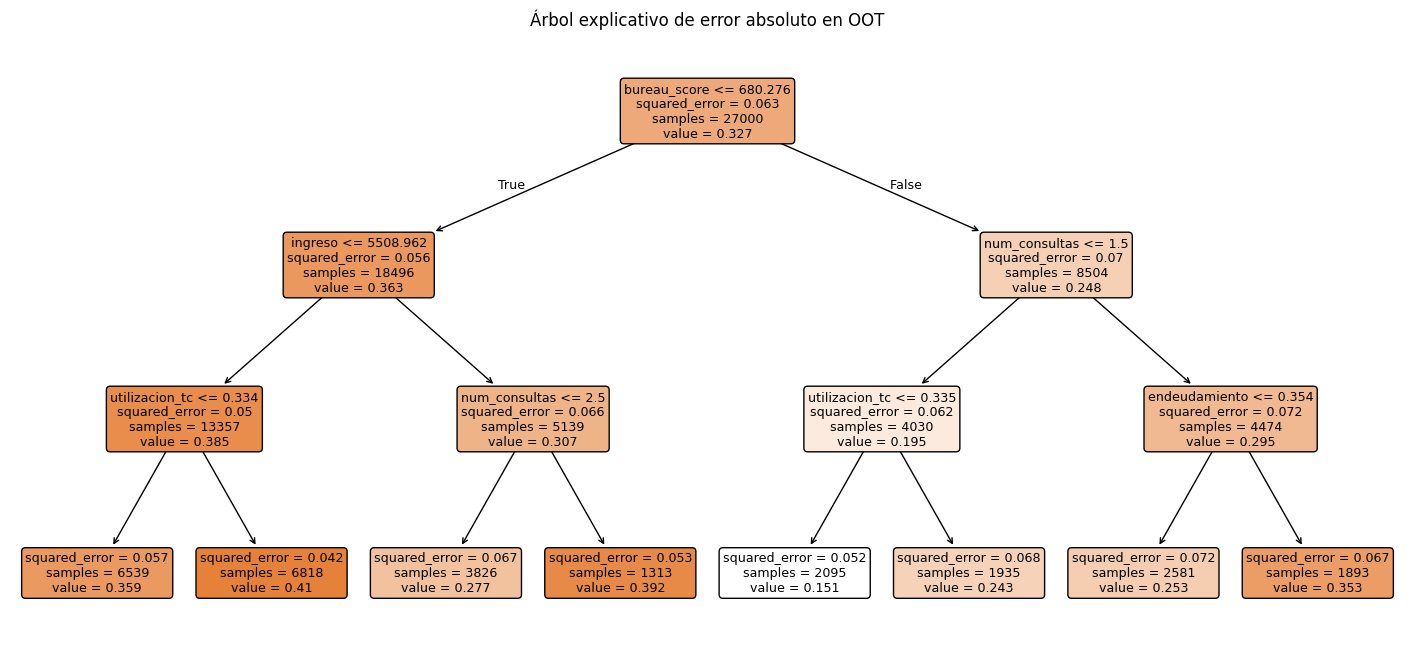

In [35]:
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.preprocessing import OneHotEncoder

seg_df = oot_monitor.copy()
seg_df['abs_error'] = np.abs(seg_df[target] - seg_df['pd_pred'])
seg_df['under_prediction'] = seg_df[target] - seg_df['pd_pred']

seg_X = pd.get_dummies(seg_df[features], dummy_na=True)
seg_X = seg_X.fillna(seg_X.median(numeric_only=True))
seg_y = seg_df['abs_error']

tree_error = DecisionTreeRegressor(max_depth=3, min_samples_leaf=400, random_state=RANDOM_STATE)
tree_error.fit(seg_X, seg_y)

print(export_text(tree_error, feature_names=list(seg_X.columns)))

plt.figure(figsize=(18,8))
plot_tree(tree_error, feature_names=seg_X.columns, filled=True, rounded=True, max_depth=3)
plt.title('Árbol explicativo de error absoluto en OOT')
plt.show()


## Matriz de riesgo: bad rate vs Gini por segmento

In [36]:
plot_seg = seg_combo.copy()
plot_seg['segmento'] = plot_seg[['producto','canal','region']].astype(str).agg(' | '.join, axis=1)

fig = px.scatter(
    plot_seg,
    x='gini', y='bad_rate', size='n', color='calibration_ratio', hover_name='segmento',
    title='Segmentos OOT: Gini bajo y bad rate alto',
    labels={'gini':'Gini del segmento', 'bad_rate':'Default observado', 'calibration_ratio':'Real/Pred'}
)
fig.add_hline(y=RISK_APPETITE_BAD_RATE, line_dash='dash', annotation_text='Apetito de riesgo')
fig.update_layout(yaxis_tickformat='.1%')
fig.show()

plot_seg.sort_values(['bad_rate','gini'], ascending=[False, True]).head(15)


,producto,canal,region,n,bad_rate,pd_media,calibration_ratio,auc,gini,segmento
13,PYME,Digital,Norte,407,0.4275,0.3382,1.2641,0.7556,0.5111,PYME | Digital | Norte
6,CE,Digital,Norte,674,0.3754,0.3237,1.1598,0.7378,0.4755,CE | Digital | Norte
14,PYME,Digital,Sur,311,0.3633,0.2954,1.2300,0.7755,0.5509,PYME | Digital | Sur
1,CE,Agencia,Norte,451,0.3592,0.2856,1.2576,0.7274,0.4547,CE | Agencia | Norte
12,PYME,Digital,Lima,989,0.3468,0.3033,1.1436,0.7219,0.4439,PYME | Digital | Lima
4,CE,Digital,Centro,360,0.3444,0.2866,1.2020,0.7355,0.4710,CE | Digital | Centro
24,TC,Digital,Oriente,388,0.3428,0.2963,1.1570,0.7530,0.5060,TC | Digital | Oriente
2,CE,Agencia,Sur,313,0.3291,0.2789,1.1799,0.7092,0.4184,CE | Agencia | Sur
23,TC,Digital,Norte,980,0.3184,0.2966,1.0736,0.7353,0.4706,TC | Digital | Norte
27,TC,Televentas,Norte,401,0.3042,0.2773,1.0972,0.7882,0.5764,TC | Televentas | Norte


# explicar caída del Gini

## Permutation importance por periodo

Si una variable reduce su importancia en OOT, puede ser señal de pérdida de relación, drift o cambio de política comercial.

In [37]:
# Para ahorrar tiempo, se muestrea cada ventana
sample_train_idx = train.sample(min(8000, len(train)), random_state=RANDOM_STATE).index
sample_oot_idx = oot.sample(min(8000, len(oot)), random_state=RANDOM_STATE).index

perm_train = permutation_importance(
    model, base.loc[sample_train_idx, features], base.loc[sample_train_idx, target],
    n_repeats=5, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1
)
perm_oot = permutation_importance(
    model, base.loc[sample_oot_idx, features], base.loc[sample_oot_idx, target],
    n_repeats=5, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1
)

perm_df = pd.DataFrame({
    'variable': features,
    'importance_train': perm_train.importances_mean,
    'importance_oot': perm_oot.importances_mean
})
perm_df['delta_oot_train'] = perm_df['importance_oot'] - perm_df['importance_train']
perm_df = perm_df.sort_values('delta_oot_train')

fig = px.bar(perm_df, x='delta_oot_train', y='variable', orientation='h', title='Cambio de permutation importance: OOT - Train')
fig.show()
perm_df


,variable,importance_train,importance_oot,delta_oot_train
1,ingreso,0.0567,0.0429,-0.0138
5,antiguedad_laboral,0.0207,0.0076,-0.0131
3,utilizacion_tc,0.0416,0.0292,-0.0124
0,edad,0.0095,-0.0012,-0.0107
4,endeudamiento,0.0287,0.0181,-0.0106
2,bureau_score,0.0974,0.0888,-0.0085
8,producto,0.0115,0.0041,-0.0074
10,region,0.0083,0.0027,-0.0056
9,canal,0.0056,0.0018,-0.0037
7,mora_hist_12m,0.0214,0.0202,-0.0012


## SHAP para explicar diferencias entre Train y OOT

Se comparan contribuciones SHAP medias absolutas entre Train y OOT. También se puede usar SHAP contra un background fijo, como el top 1% de mejores clientes.

In [38]:
# Preparar matriz transformada para SHAP
pre = model.named_steps['preprocess']
final_model = model.named_steps['model']

X_train_trans = pre.transform(X_train_raw)
X_oot_trans = pre.transform(X_oot_raw)

# nombres después del one-hot
try:
    feature_names_trans = pre.get_feature_names_out()
except Exception:
    feature_names_trans = [f'x{i}' for i in range(X_train_trans.shape[1])]

# Muestras para SHAP
rng = np.random.default_rng(RANDOM_STATE)
idx_tr = rng.choice(X_train_trans.shape[0], size=min(1500, X_train_trans.shape[0]), replace=False)
idx_oo = rng.choice(X_oot_trans.shape[0], size=min(1500, X_oot_trans.shape[0]), replace=False)

if HAS_SHAP:
    # Background fijo: top 1% mejores clientes de train según menor PD
    train_monitor = monitor[monitor['periodo'].isin(TRAIN_MONTHS)].copy()
    cutoff_top = train_monitor['pd_pred'].quantile(TOP_PERCENTILE)
    top1_idx_raw = train_monitor[train_monitor['pd_pred'] <= cutoff_top].index
    top1_idx_raw = top1_idx_raw.intersection(train.index)
    top1_trans = pre.transform(base.loc[top1_idx_raw, features])
    if top1_trans.shape[0] > 500:
        top1_trans = top1_trans[rng.choice(top1_trans.shape[0], 500, replace=False)]

    explainer = shap.TreeExplainer(final_model, data=top1_trans, model_output='probability')
    shap_train = explainer.shap_values(X_train_trans[idx_tr])
    shap_oot = explainer.shap_values(X_oot_trans[idx_oo])

    def to_2d_shap(sv):
        arr = np.array(sv)
        if isinstance(sv, list):
            return sv[1]
        if arr.ndim == 3:
            return arr[:, :, 1]
        return arr

    shap_train_2d = to_2d_shap(shap_train)
    shap_oot_2d = to_2d_shap(shap_oot)

    shap_imp = pd.DataFrame({
        'variable_trans': feature_names_trans,
        'mean_abs_shap_train': np.abs(shap_train_2d).mean(axis=0),
        'mean_abs_shap_oot': np.abs(shap_oot_2d).mean(axis=0),
        'mean_shap_train': shap_train_2d.mean(axis=0),
        'mean_shap_oot': shap_oot_2d.mean(axis=0)
    })
    shap_imp['delta_abs_oot_train'] = shap_imp['mean_abs_shap_oot'] - shap_imp['mean_abs_shap_train']
    shap_imp['delta_mean_oot_train'] = shap_imp['mean_shap_oot'] - shap_imp['mean_shap_train']
    shap_imp = shap_imp.sort_values('delta_abs_oot_train', ascending=False)

    display(shap_imp.head(20))

    fig = px.bar(
        shap_imp.head(20).sort_values('delta_abs_oot_train'),
        x='delta_abs_oot_train', y='variable_trans', orientation='h',
        title='Variables que más aumentan su contribución SHAP absoluta en OOT vs Train'
    )
    fig.show()
else:
    print('SHAP no está instalado. Ejecuta: !pip install shap')


 97%|=================== | 1448/1500 [00:16<00:00]       

,variable_trans,mean_abs_shap_train,mean_abs_shap_oot,mean_shap_train,mean_shap_oot,delta_abs_oot_train,delta_mean_oot_train
2,num__bureau_score,0.0507,0.0822,0.0500,0.0816,0.0315,0.0317
1,num__ingreso,0.0358,0.0510,0.0343,0.0494,0.0152,0.0151
6,num__num_consultas,0.0134,0.0282,0.0099,0.0251,0.0149,0.0152
3,num__utilizacion_tc,0.0189,0.0313,0.0158,0.0290,0.0124,0.0132
7,num__mora_hist_12m,0.0096,0.0203,0.0075,0.0181,0.0107,0.0106
4,num__endeudamiento,0.0121,0.0210,0.0081,0.0180,0.0089,0.0099
5,num__antiguedad_laboral,0.0173,0.0245,0.0155,0.0227,0.0072,0.0072
10,cat__producto_PYME,0.0031,0.0046,0.0015,0.0025,0.0015,0.0009
18,cat__region_Norte,0.0036,0.0048,0.0023,0.0031,0.0012,0.0008
14,cat__canal_Digital,0.0026,0.0038,0.0004,0.0011,0.0011,0.0006


## SHAP por mes OOT: evolución de contribuciones

In [39]:
if HAS_SHAP:
    shap_month_rows = []
    for m in OOT_MONTHS:
        df_m = base[base['periodo'] == m]
        X_m_trans = pre.transform(df_m[features])
        idx_m = rng.choice(X_m_trans.shape[0], size=min(800, X_m_trans.shape[0]), replace=False)
        sv_m = to_2d_shap(explainer.shap_values(X_m_trans[idx_m]))
        temp = pd.DataFrame({
            'periodo': m,
            'variable_trans': feature_names_trans,
            'mean_abs_shap': np.abs(sv_m).mean(axis=0),
            'mean_shap': sv_m.mean(axis=0)
        })
        shap_month_rows.append(temp)
    shap_month = pd.concat(shap_month_rows, ignore_index=True)

    top_vars_shap = shap_imp.head(12)['variable_trans'].tolist()
    fig = px.line(
        shap_month[shap_month['variable_trans'].isin(top_vars_shap)],
        x='periodo', y='mean_abs_shap', color='variable_trans', markers=True,
        title='Evolución mensual OOT de importancia SHAP absoluta'
    )
    fig.show()
    display(shap_month.sort_values(['periodo','mean_abs_shap'], ascending=[True, False]).head(30))


,periodo,variable_trans,mean_abs_shap,mean_shap
2,2025-01,num__bureau_score,0.0586,0.0580
1,2025-01,num__ingreso,0.0392,0.0377
3,2025-01,num__utilizacion_tc,0.0221,0.0194
5,2025-01,num__antiguedad_laboral,0.0189,0.0170
6,2025-01,num__num_consultas,0.0164,0.0130
4,2025-01,num__endeudamiento,0.0134,0.0094
7,2025-01,num__mora_hist_12m,0.0124,0.0105
18,2025-01,cat__region_Norte,0.0036,0.0022
10,2025-01,cat__producto_PYME,0.0030,0.0014
14,2025-01,cat__canal_Digital,0.0029,0.0006


Diagnóstico integrado de caída del Gini.

PSI, IV y cambio de SHAP/permutation importance.

In [40]:
# Resumen por variable original
psi_summary = psi_df.groupby('variable')['psi'].max().rename('max_psi_oot')
iv_train_mean = iv_df[iv_df['periodo'].isin(TRAIN_MONTHS)].groupby('variable')['iv'].mean().rename('iv_train_mean')
iv_oot_mean = iv_df[iv_df['periodo'].isin(OOT_MONTHS)].groupby('variable')['iv'].mean().rename('iv_oot_mean')
perm_summary = perm_df.set_index('variable')[['importance_train','importance_oot','delta_oot_train']]

diagnosis = pd.concat([psi_summary, iv_train_mean, iv_oot_mean, perm_summary], axis=1).reset_index()
diagnosis['delta_iv_oot_train'] = diagnosis['iv_oot_mean'] - diagnosis['iv_train_mean']
diagnosis['alerta_posible_causa_caida'] = np.where(
    (diagnosis['max_psi_oot'] > 0.10) | (diagnosis['delta_iv_oot_train'] < -0.03) | (diagnosis['delta_oot_train'] < -0.005),
    1, 0
)

diagnosis.sort_values(['alerta_posible_causa_caida','delta_oot_train'], ascending=[False, True])


,variable,max_psi_oot,iv_train_mean,iv_oot_mean,importance_train,importance_oot,delta_oot_train,delta_iv_oot_train,alerta_posible_causa_caida
5,ingreso,0.0279,0.1534,0.1472,0.0567,0.0429,-0.0138,-0.0062,1
0,antiguedad_laboral,0.0240,0.0437,0.0370,0.0207,0.0076,-0.0131,-0.0067,1
10,utilizacion_tc,0.3293,0.1072,0.0891,0.0416,0.0292,-0.0124,-0.0181,1
3,edad,0.0404,0.0130,0.0083,0.0095,-0.0012,-0.0107,-0.0047,1
4,endeudamiento,0.3136,0.0757,0.0753,0.0287,0.0181,-0.0106,-0.0003,1
1,bureau_score,0.2096,0.3136,0.2589,0.0974,0.0888,-0.0085,-0.0547,1
8,producto,0.0007,0.0233,0.0201,0.0115,0.0041,-0.0074,-0.0032,1
9,region,0.0028,0.0168,0.0145,0.0083,0.0027,-0.0056,-0.0023,1
6,mora_hist_12m,0.2275,0.0256,0.0409,0.0214,0.0202,-0.0012,0.0153,1
7,num_consultas,0.5350,0.0677,0.0983,0.0319,0.0325,0.0006,0.0306,1


# grupo con default superior al apetito, pero PD calibrada e insuficiente para excluir

## Definición de política: umbral de exclusión y apetito

Supongamos que la política excluye clientes con PD >= percentil 90 de Train. Buscamos segmentos que:

1. Estén por debajo del umbral de exclusión.
2. Tengan bad rate observado mayor al apetito de riesgo.
3. Tengan calibración razonable: bad rate / PD media cerca de 1.
4. No fueron excluidos porque su PD promedio no fue suficientemente alta.

In [41]:
PD_EXCLUSION_THRESHOLD = train_pd.quantile(0.90)
CALIBRATION_LOWER = 0.85
CALIBRATION_UPPER = 1.15

print('Umbral de exclusión por PD:', PD_EXCLUSION_THRESHOLD)

eligible = oot_monitor[oot_monitor['pd_pred'] < PD_EXCLUSION_THRESHOLD].copy()

candidate_segments = segment_performance(eligible, ['producto','canal','region'], min_n=MIN_SEGMENT_SIZE)
candidate_segments['segmento'] = candidate_segments[['producto','canal','region']].astype(str).agg(' | '.join, axis=1)

candidate_segments['supera_apetito'] = candidate_segments['bad_rate'] > RISK_APPETITE_BAD_RATE
candidate_segments['calibrado'] = candidate_segments['calibration_ratio'].between(CALIBRATION_LOWER, CALIBRATION_UPPER)
candidate_segments['pd_insuficiente_para_excluir'] = candidate_segments['pd_media'] < PD_EXCLUSION_THRESHOLD

findings = candidate_segments[
    candidate_segments['supera_apetito'] &
    candidate_segments['calibrado'] &
    candidate_segments['pd_insuficiente_para_excluir']
].sort_values('bad_rate', ascending=False)

findings.head(20)


Umbral de exclusión por PD: 0.3310138862629993


,producto,canal,region,n,bad_rate,pd_media,calibration_ratio,auc,gini,segmento,supera_apetito,calibrado,pd_insuficiente_para_excluir
2,CE,Digital,Lima,1247,0.1844,0.1681,1.0974,0.6514,0.3029,CE | Digital | Lima,True,True,True
15,TC,Digital,Lima,1696,0.1810,0.1648,1.0983,0.6517,0.3034,TC | Digital | Lima,True,True,True
8,PYME,Agencia,Lima,425,0.1788,0.1670,1.0705,0.6553,0.3107,PYME | Agencia | Lima,True,True,True
12,TC,Agencia,Sur,343,0.1749,0.1582,1.1057,0.7055,0.4111,TC | Agencia | Sur,True,True,True
14,TC,Digital,Centro,350,0.1629,0.1643,0.9915,0.6632,0.3264,TC | Digital | Centro,True,True,True
13,TC,Aliado,Lima,386,0.1451,0.1392,1.0424,0.6228,0.2457,TC | Aliado | Lima,True,True,True


## Visualización del hallazgo de apetito de riesgo

In [42]:
fig = px.scatter(
    candidate_segments,
    x='pd_media', y='bad_rate', size='n', color='calibration_ratio',
    hover_name='segmento', title='Segmentos elegibles: bad rate vs PD media',
    labels={'pd_media':'PD promedio del segmento', 'bad_rate':'Default observado', 'calibration_ratio':'Real/Pred'}
)
fig.add_hline(y=RISK_APPETITE_BAD_RATE, line_dash='dash', annotation_text='Apetito de riesgo')
fig.add_vline(x=PD_EXCLUSION_THRESHOLD, line_dash='dash', annotation_text='Umbral exclusión PD')
fig.add_trace(go.Scatter(x=[0, max(candidate_segments['pd_media'].max(), candidate_segments['bad_rate'].max())],
                         y=[0, max(candidate_segments['pd_media'].max(), candidate_segments['bad_rate'].max())],
                         mode='lines', name='Calibración perfecta', line=dict(dash='dot')))
fig.update_layout(xaxis_tickformat='.1%', yaxis_tickformat='.1%')
fig.show()

if len(findings) > 0:
    display(findings[['segmento','n','bad_rate','pd_media','calibration_ratio','gini']].head(10))
else:
    print('No se encontraron segmentos que cumplan simultáneamente las condiciones. Ajusta apetito, umbral o granularidad.')


,segmento,n,bad_rate,pd_media,calibration_ratio,gini
2,CE | Digital | Lima,1247,0.1844,0.1681,1.0974,0.3029
15,TC | Digital | Lima,1696,0.1810,0.1648,1.0983,0.3034
8,PYME | Agencia | Lima,425,0.1788,0.1670,1.0705,0.3107
12,TC | Agencia | Sur,343,0.1749,0.1582,1.1057,0.4111
14,TC | Digital | Centro,350,0.1629,0.1643,0.9915,0.3264
13,TC | Aliado | Lima,386,0.1451,0.1392,1.0424,0.2457


## Profundización del segmento hallado

In [43]:
if len(findings) > 0:
    selected = findings.iloc[0]
    mask_selected = (
        (eligible['producto'] == selected['producto']) &
        (eligible['canal'] == selected['canal']) &
        (eligible['region'] == selected['region'])
    )
    seg_selected = eligible[mask_selected].copy()
    print('Segmento seleccionado:', selected['segmento'])
    print('N:', len(seg_selected))
    print('Bad rate:', seg_selected[target].mean())
    print('PD media:', seg_selected['pd_pred'].mean())
    print('Ratio real/pred:', seg_selected[target].mean()/seg_selected['pd_pred'].mean())

    # Evolución mensual del segmento
    seg_month = seg_selected.groupby('periodo').agg(
        n=('default','size'),
        bad_rate=('default','mean'),
        pd_media=('pd_pred','mean')
    ).reset_index()
    fig = px.line(seg_month, x='periodo', y=['bad_rate','pd_media'], markers=True, title='Evolución del segmento seleccionado')
    fig.add_hline(y=RISK_APPETITE_BAD_RATE, line_dash='dash', annotation_text='Apetito')
    fig.update_layout(yaxis_tickformat='.1%')
    fig.show()

    # Distribución de PD: no cruza el umbral lo suficiente
    fig = px.histogram(seg_selected, x='pd_pred', nbins=40, title='Distribución de PD en segmento seleccionado')
    fig.add_vline(x=PD_EXCLUSION_THRESHOLD, line_dash='dash', annotation_text='Umbral exclusión')
    fig.show()


Segmento seleccionado: CE | Digital | Lima
N: 1247
Bad rate: 0.18444266238973536
PD media: 0.1680716204336861
Ratio real/pred: 1.0974051533138434


## SHAP del segmento hallado vs resto OOT elegible

In [44]:
if HAS_SHAP and len(findings) > 0:
    rest_eligible = eligible[~mask_selected].copy()

    X_seg_trans = pre.transform(seg_selected[features])
    X_rest_trans = pre.transform(rest_eligible[features])

    idx_seg = rng.choice(X_seg_trans.shape[0], size=min(800, X_seg_trans.shape[0]), replace=False)
    idx_rest = rng.choice(X_rest_trans.shape[0], size=min(800, X_rest_trans.shape[0]), replace=False)

    sv_seg = to_2d_shap(explainer.shap_values(X_seg_trans[idx_seg]))
    sv_rest = to_2d_shap(explainer.shap_values(X_rest_trans[idx_rest]))

    seg_shap_diff = pd.DataFrame({
        'variable_trans': feature_names_trans,
        'mean_shap_segmento': sv_seg.mean(axis=0),
        'mean_shap_resto': sv_rest.mean(axis=0),
        'mean_abs_shap_segmento': np.abs(sv_seg).mean(axis=0),
        'mean_abs_shap_resto': np.abs(sv_rest).mean(axis=0)
    })
    seg_shap_diff['delta_mean_shap'] = seg_shap_diff['mean_shap_segmento'] - seg_shap_diff['mean_shap_resto']
    seg_shap_diff['delta_abs_shap'] = seg_shap_diff['mean_abs_shap_segmento'] - seg_shap_diff['mean_abs_shap_resto']
    seg_shap_diff = seg_shap_diff.sort_values('delta_mean_shap', ascending=False)

    fig = px.bar(
        seg_shap_diff.head(20).sort_values('delta_mean_shap'),
        x='delta_mean_shap', y='variable_trans', orientation='h',
        title='Qué explica que el segmento tenga mayor riesgo vs resto elegible'
    )
    fig.show()
    display(seg_shap_diff.head(20))


,variable_trans,mean_shap_segmento,mean_shap_resto,mean_abs_shap_segmento,mean_abs_shap_resto,delta_mean_shap,delta_abs_shap
14,cat__canal_Digital,0.0046,0.0002,0.0046,0.0027,0.0044,0.0019
1,num__ingreso,0.0336,0.0297,0.0355,0.0318,0.0039,0.0037
2,num__bureau_score,0.0475,0.0453,0.0480,0.0461,0.0022,0.0019
8,cat__producto_CE,0.0018,0.0004,0.0018,0.0007,0.0014,0.0011
9,cat__producto_Hipotecario,0.0020,0.0006,0.0020,0.0023,0.0014,-0.0003
4,num__endeudamiento,0.0105,0.0093,0.0133,0.0126,0.0012,0.0007
11,cat__producto_TC,0.0010,0.0002,0.0010,0.0009,0.0007,0.0001
20,cat__region_Sur,0.0007,0.0001,0.0007,0.0006,0.0005,0.0000
6,num__num_consultas,0.0129,0.0125,0.0157,0.0151,0.0003,0.0006
13,cat__canal_Aliado,0.0003,0.0001,0.0003,0.0003,0.0002,-0.0000


# resumen ejecutivo automático

In [45]:
last_oot = perf_df[perf_df['periodo'].isin(OOT_MONTHS)].iloc[-1]
first_oot = perf_df[perf_df['periodo'].isin(OOT_MONTHS)].iloc[0]
train_avg_gini = perf_df[perf_df['periodo'].isin(TRAIN_MONTHS)]['gini'].mean()
oot_avg_gini = perf_df[perf_df['periodo'].isin(OOT_MONTHS)]['gini'].mean()

top_psi = psi_df.sort_values('psi', ascending=False).head(5)
top_diag = diagnosis.sort_values(['alerta_posible_causa_caida','delta_oot_train'], ascending=[False, True]).head(5)

print('================ RESUMEN EJECUTIVO ================')
print(f'Gini promedio Train: {train_avg_gini:.3f}')
print(f'Gini promedio OOT  : {oot_avg_gini:.3f}')
print(f'Delta Gini OOT-Train: {oot_avg_gini-train_avg_gini:.3f}')
print(f'Gini primer OOT ({first_oot.periodo}): {first_oot.gini:.3f}')
print(f'Gini último OOT ({last_oot.periodo}): {last_oot.gini:.3f}')
print('================================')
print('Variables con mayor PSI OOT:')
print(top_psi[['periodo','variable','psi']].to_string(index=False))
print('Variables sospechosas por PSI/IV/Permutation:')
print(top_diag[['variable','max_psi_oot','delta_iv_oot_train','delta_oot_train','alerta_posible_causa_caida']].to_string(index=False))
print('================================')
if len(findings) > 0:
    print('Segmentos que superan apetito, están calibrados y no fueron excluidos:')
    print(findings[['segmento','n','bad_rate','pd_media','calibration_ratio','gini']].head(5).to_string(index=False))
else:
    print('No se encontraron segmentos con las tres condiciones de apetito/calibración/no exclusión.')


================ RESUMEN EJECUTIVO ================
Gini promedio Train: 0.570
Gini promedio OOT  : 0.483
Delta Gini OOT-Train: -0.088
Gini primer OOT (2025-01): 0.480
Gini último OOT (2025-06): 0.480
Variables con mayor PSI OOT:
periodo       variable    psi
2025-06  num_consultas 0.5350
2025-05  num_consultas 0.4072
2025-06 utilizacion_tc 0.3293
2025-06  endeudamiento 0.3136
2025-04  num_consultas 0.2699
Variables sospechosas por PSI/IV/Permutation:
          variable  max_psi_oot  delta_iv_oot_train  delta_oot_train  alerta_posible_causa_caida
           ingreso       0.0279             -0.0062          -0.0138                           1
antiguedad_laboral       0.0240             -0.0067          -0.0131                           1
    utilizacion_tc       0.3293             -0.0181          -0.0124                           1
              edad       0.0404             -0.0047          -0.0107                           1
     endeudamiento       0.3136             -0.0003        